# FGO run analysis — all runs in `runs/`

This notebook reads every run directory in `runs/` and compares them on one consistent
footing: final objective value, convergence, objective decomposition, search behaviour,
population dynamics and the best networks found.

**Data sources (per run):** `manifest.json` (instance, config, baseline), `summary.json`
(final score, budget, runtime), `best.json` (best metrics + decoded graph),
`history.jsonl` (one record per evaluation), `snapshots.jsonl` (population fitness
statistics over time).

**How to run:** start Jupyter in the repository root (or any of its subdirectories) and run
all cells (`jupyter lab runs_analysis.ipynb` or `jupyter nbconvert --execute --inplace runs_analysis.ipynb`).
The notebook locates `runs/` by walking up the working directory.
It needs only NumPy, Matplotlib and SciPy; it does not import `grzybki`.
Figures are also written to `runs/_analysis/` (set `SAVE_FIGURES = False` to disable).

**Fairness caveat.** The runs do not share the same evaluation budget: 15–100 terminals
used 20,000 evaluations, 500 used 1,500, 1,000 used 1,000 and 5,000 used 120 (see §1).
Raw final `J` values are therefore *not* directly comparable across sizes. Where that
matters the notebook compares runs at a **common budget of 120 evaluations** (the
smallest budget present) and against each run's own starting point.

## 0. Setup

In [1]:
from pathlib import Path
import json
import os

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

try:  # only available inside Jupyter
    from IPython.display import display, Markdown
except ImportError:  # plain-python fallback so the cells stay executable
    def display(obj=None, *args, **kwargs):
        print(obj)

    def Markdown(text):
        return text

RUNS_DIR = Path.cwd() / "runs"
for _base in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (_base / "runs").is_dir():
        RUNS_DIR = _base / "runs"
        break
OUT_DIR = RUNS_DIR / "_analysis"
SAVE_FIGURES = True
DPI = 150
COMMON_BUDGET = 120  # smallest budget in runs/, so every run reaches it

FAMILY_ORDER = ["polygon", "ring", "grid", "uniform", "clustered", "poland"]
SIZE_ORDER = [15, 30, 50, 100, 500, 1000, 5000]
FAMILY_COLOR = {
    "polygon": "#4C72B0",
    "ring": "#DD8452",
    "grid": "#55A868",
    "uniform": "#C44E52",
    "clustered": "#8172B3",
    "poland": "#937860",
}
OPERATOR_COLOR = {
    "branching": "#4C72B0",
    "germination": "#55A868",
    "exploration": "#DD8452",
    "exploitation": "#C44E52",
}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
    "legend.frameon": False,
})


def savefig(fig, name):
    if SAVE_FIGURES:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT_DIR / name, dpi=DPI, bbox_inches="tight")
    plt.show()


def md_table(headers, rows):
    lines = [
        "| " + " | ".join(str(h) for h in headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    return Markdown("\n".join(lines))


def size_color(n):
    frac = SIZE_ORDER.index(n) / (len(SIZE_ORDER) - 1)
    return plt.get_cmap("viridis")(0.15 + 0.75 * frac)


print("runs dir:", os.path.relpath(RUNS_DIR, Path.cwd()), "| exists:", RUNS_DIR.is_dir())

runs dir: runs | exists: True


In [2]:
def read_json(path):
    with open(path) as fh:
        return json.load(fh)


def read_jsonl(path):
    with open(path) as fh:
        return [json.loads(line) for line in fh if line.strip()]


def discover_run_dirs():
    # Run dirs are directories that contain a manifest and all artifacts this notebook reads.
    required = ["manifest.json", "summary.json", "best.json", "history.jsonl", "snapshots.jsonl"]
    complete, skipped = [], []
    if not RUNS_DIR.is_dir():
        return complete, skipped
    for d in sorted(RUNS_DIR.iterdir()):
        if not (d.is_dir() and (d / "manifest.json").is_file()):
            continue
        if all((d / name).is_file() for name in required):
            complete.append(d)
        else:
            skipped.append(d.name)
    return complete, skipped


def load_run(directory):
    manifest = read_json(directory / "manifest.json")
    summary = read_json(directory / "summary.json")
    best = read_json(directory / "best.json")
    history = read_jsonl(directory / "history.jsonl")
    snapshots = read_jsonl(directory / "snapshots.jsonl")

    name = directory.name
    family = name.split("_")[0]
    metrics = best["best"]["metrics"]

    hist = {
        "t": np.array([r["t"] for r in history], dtype=int),
        "best": np.array([r["best_score"] for r in history], dtype=float),
        "score": np.array([r["score"] for r in history], dtype=float),
        "accepted": np.array([bool(r["accepted"]) for r in history], dtype=bool),
        "operator": np.array([r["operator"] for r in history], dtype=object),
        "phase": np.array([r["phase"] for r in history], dtype=object),
        "J": np.array([r["details"]["metrics"]["J"] for r in history], dtype=float),
        "C": np.array([r["details"]["metrics"]["C"] for r in history], dtype=float),
        "D": np.array([r["details"]["metrics"]["D"] for r in history], dtype=float),
        "FT": np.array([r["details"]["metrics"]["FT"] for r in history], dtype=float),
    }

    snaps = {
        "t": np.array([s["t"] for s in snapshots], dtype=int),
        "best": np.array([s["best_score"] for s in snapshots], dtype=float),
        "fmin": np.array([s["fitness_min"] for s in snapshots], dtype=float),
        "fmean": np.array([s["fitness_mean"] for s in snapshots], dtype=float),
        "fmax": np.array([s["fitness_max"] for s in snapshots], dtype=float),
    }

    init_mask = hist["phase"] == "init"
    init_best = float(hist["best"][init_mask][-1]) if init_mask.any() else float(hist["best"][0])

    # best-so-far value reached at the common budget
    pos = np.searchsorted(hist["t"], COMMON_BUDGET)
    if pos < len(hist["t"]) and hist["t"][pos] == COMMON_BUDGET:
        j_common = float(hist["best"][pos])
    else:
        j_common = float(hist["best"][-1])

    return {
        "name": name,
        "dir": directory,
        "family": family,
        "n": int(manifest["instance"]["n"]),
        "K": int(manifest["problem"]["K"]),
        "dimension": int(manifest["problem"]["dimension"]),
        "crs": manifest["instance"]["crs"],
        "weights": manifest["problem"]["weights"],
        "seed": int(manifest["config"]["seed"]),
        "evals": int(summary["evaluations"]),
        "runtime": float(summary["runtime"]),
        "evals_per_s": float(summary["evaluations"]) / max(float(summary["runtime"]), 1e-9),
        "J": float(summary["best_score"]),
        "J_common": j_common,
        "J_init": init_best,
        "metrics": metrics,
        "theta": float(best["best"]["theta"]),
        "graph": best["best"]["graph"],
        "history": hist,
        "snapshots": snaps,
    }


run_dirs, skipped_dirs = discover_run_dirs()
RUNS = [load_run(d) for d in run_dirs]
assert RUNS, f"No complete run directories found under {RUNS_DIR}"

by_key = {(r["family"], r["n"]): r for r in RUNS}
families = [f for f in FAMILY_ORDER if any(r["family"] == f for r in RUNS)]
sizes = [s for s in SIZE_ORDER if any(r["n"] == s for r in RUNS)]
evals_by_size = {s: sorted({r["evals"] for r in RUNS if r["n"] == s}) for s in sizes}

print(f"loaded {len(RUNS)} runs | families: {', '.join(families)} | sizes: {sizes}")
print(f"history records: {sum(len(r['history']['t']) for r in RUNS):,}")
if skipped_dirs:
    print(f"skipped incomplete runs (missing artifacts): {', '.join(skipped_dirs)}")
for s in sizes:
    print(f"  n={s:>4}: {sum(1 for r in RUNS if r['n'] == s)} runs, budgets {evals_by_size[s]}")

loaded 42 runs | families: polygon, ring, grid, uniform, clustered, poland | sizes: [15, 30, 50, 100, 500, 1000, 5000]
history records: 495,720
  n=  15: 6 runs, budgets [20000]
  n=  30: 6 runs, budgets [20000]
  n=  50: 6 runs, budgets [20000]
  n= 100: 6 runs, budgets [20000]
  n= 500: 6 runs, budgets [1500]
  n=1000: 6 runs, budgets [1000]
  n=5000: 6 runs, budgets [120]


## 1. Run inventory, budgets and cost

42 runs: 6 instance families × 7 sizes, all with seed 42 and the same FGO defaults
(`population=30`, `M=0.6`, `Ep=0.7`, `R=0.9`, `w=(0.4, 0.4, 0.2)`). The budget was cut for
large instances, so **wall-clock and evaluation budgets differ by more than two orders of
magnitude** — this is the single most important confounder in any cross-run comparison.

In [3]:
rows = []
for r in sorted(RUNS, key=lambda r: (FAMILY_ORDER.index(r["family"]), r["n"])):
    rows.append([
        f"`{r['name']}`", r["n"], r["K"], f"{r['evals']:,}",
        f"{r['runtime']:,.0f}", f"{r['evals_per_s']:.1f}",
        f"{r['J']:.4f}", f"{r['J_init']:.4f}",
        f"{r['J_init'] - r['J']:+.4f}", f"{r['theta']:.4f}",
    ])
display(md_table(
    ["run", "n", "K", "evals", "runtime [s]", "evals/s", "final J", "J after init",
     "ΔJ (init→final)", "θ"],
    rows,
))

| run | n | K | evals | runtime [s] | evals/s | final J | J after init | ΔJ (init→final) | θ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| `polygon_15_seed42` | 15 | 13 | 20,000 | 26 | 758.4 | 0.7078 | 0.9686 | +0.2607 | 0.0757 |
| `polygon_30_seed42` | 30 | 28 | 20,000 | 46 | 434.1 | 0.6905 | 0.9158 | +0.2253 | 0.0212 |
| `polygon_50_seed42` | 50 | 48 | 20,000 | 94 | 213.4 | 0.6835 | 0.7488 | +0.0653 | 0.0122 |
| `polygon_100_seed42` | 100 | 98 | 20,000 | 522 | 38.3 | 0.6785 | 0.9784 | +0.2999 | 0.0064 |
| `polygon_500_seed42` | 500 | 498 | 1,500 | 1,022 | 1.5 | 0.6780 | 1.0423 | +0.3643 | 0.0024 |
| `polygon_1000_seed42` | 1000 | 200 | 1,000 | 926 | 1.1 | 0.6745 | 0.9619 | +0.2875 | 0.0011 |
| `polygon_5000_seed42` | 5000 | 200 | 120 | 1,880 | 0.1 | 0.7624 | 1.6926 | +0.9302 | 0.0090 |
| `ring_15_seed42` | 15 | 13 | 20,000 | 25 | 788.1 | 0.7188 | 1.0655 | +0.3468 | 0.0424 |
| `ring_30_seed42` | 30 | 28 | 20,000 | 52 | 388.1 | 0.7033 | 1.0025 | +0.2991 | 0.0196 |
| `ring_50_seed42` | 50 | 48 | 20,000 | 135 | 147.9 | 0.7223 | 1.0216 | +0.2993 | 0.0254 |
| `ring_100_seed42` | 100 | 98 | 20,000 | 551 | 36.3 | 0.9644 | 1.0970 | +0.1327 | 0.0476 |
| `ring_500_seed42` | 500 | 498 | 1,500 | 1,169 | 1.3 | 0.9678 | 1.0472 | +0.0793 | 0.0267 |
| `ring_1000_seed42` | 1000 | 200 | 1,000 | 1,071 | 0.9 | 0.9604 | 0.9808 | +0.0204 | 0.0797 |
| `ring_5000_seed42` | 5000 | 200 | 120 | 3,403 | 0.0 | 0.9595 | 0.9649 | +0.0053 | 0.1210 |
| `grid_15_seed42` | 15 | 13 | 20,000 | 31 | 645.7 | 0.8200 | 1.0150 | +0.1950 | 0.0772 |
| `grid_30_seed42` | 30 | 28 | 20,000 | 65 | 305.9 | 0.8614 | 0.9712 | +0.1098 | 0.0754 |
| `grid_50_seed42` | 50 | 48 | 20,000 | 100 | 199.6 | 0.8601 | 0.9948 | +0.1348 | 0.0602 |
| `grid_100_seed42` | 100 | 98 | 20,000 | 502 | 39.9 | 0.8747 | 0.9662 | +0.0914 | 0.1112 |
| `grid_500_seed42` | 500 | 498 | 1,500 | 1,098 | 1.4 | 0.9043 | 1.0111 | +0.1068 | 0.1375 |
| `grid_1000_seed42` | 1000 | 200 | 1,000 | 1,233 | 0.8 | 0.8685 | 0.9045 | +0.0360 | 0.2423 |
| `grid_5000_seed42` | 5000 | 200 | 120 | 2,617 | 0.0 | 0.9536 | 0.9556 | +0.0019 | 0.4857 |
| `uniform_15_seed42` | 15 | 13 | 20,000 | 24 | 823.9 | 0.9011 | 1.0433 | +0.1422 | 0.1366 |
| `uniform_30_seed42` | 30 | 28 | 20,000 | 48 | 413.8 | 0.8984 | 1.0687 | +0.1703 | 0.1108 |
| `uniform_50_seed42` | 50 | 48 | 20,000 | 132 | 151.4 | 0.9583 | 1.1374 | +0.1791 | 0.0562 |
| `uniform_100_seed42` | 100 | 98 | 20,000 | 524 | 38.2 | 0.9253 | 1.1062 | +0.1809 | 0.1494 |
| `uniform_500_seed42` | 500 | 498 | 1,500 | 1,172 | 1.3 | 0.9970 | 1.1138 | +0.1168 | 0.0346 |
| `uniform_1000_seed42` | 1000 | 200 | 1,000 | 1,140 | 0.9 | 0.9463 | 1.0289 | +0.0826 | 0.0629 |
| `uniform_5000_seed42` | 5000 | 200 | 120 | 3,848 | 0.0 | 0.9035 | 0.9035 | +0.0000 | 0.1575 |
| `clustered_15_seed42` | 15 | 13 | 20,000 | 28 | 720.5 | 0.9440 | 1.0418 | +0.0978 | 0.0624 |
| `clustered_30_seed42` | 30 | 28 | 20,000 | 56 | 360.3 | 0.8972 | 1.0018 | +0.1045 | 0.0771 |
| `clustered_50_seed42` | 50 | 48 | 20,000 | 97 | 205.6 | 0.9254 | 0.9664 | +0.0410 | 0.0609 |
| `clustered_100_seed42` | 100 | 98 | 20,000 | 532 | 37.6 | 0.9321 | 1.1760 | +0.2439 | 0.0536 |
| `clustered_500_seed42` | 500 | 498 | 1,500 | 1,144 | 1.3 | 0.9775 | 1.1183 | +0.1407 | 0.0718 |
| `clustered_1000_seed42` | 1000 | 200 | 1,000 | 1,394 | 0.7 | 0.9502 | 0.9887 | +0.0385 | 0.0806 |
| `clustered_5000_seed42` | 5000 | 200 | 120 | 4,052 | 0.0 | 0.9441 | 0.9616 | +0.0175 | 0.0631 |
| `poland_15_seed42` | 15 | 13 | 20,000 | 19 | 1078.8 | 0.8985 | 1.0297 | +0.1312 | 0.0656 |
| `poland_30_seed42` | 30 | 28 | 20,000 | 55 | 365.2 | 0.8947 | 1.0506 | +0.1559 | 0.0818 |
| `poland_50_seed42` | 50 | 48 | 20,000 | 121 | 165.9 | 0.9235 | 1.0896 | +0.1661 | 0.0959 |
| `poland_100_seed42` | 100 | 98 | 20,000 | 565 | 35.4 | 0.9075 | 1.0663 | +0.1588 | 0.0842 |
| `poland_500_seed42` | 500 | 498 | 1,500 | 1,107 | 1.4 | 0.9226 | 1.0389 | +0.1163 | 0.0386 |
| `poland_1000_seed42` | 1000 | 200 | 1,000 | 1,135 | 0.9 | 0.9442 | 0.9820 | +0.0379 | 0.1299 |
| `poland_5000_seed42` | 5000 | 200 | 120 | 3,712 | 0.0 | 0.9280 | 0.9382 | +0.0102 | 0.1990 |

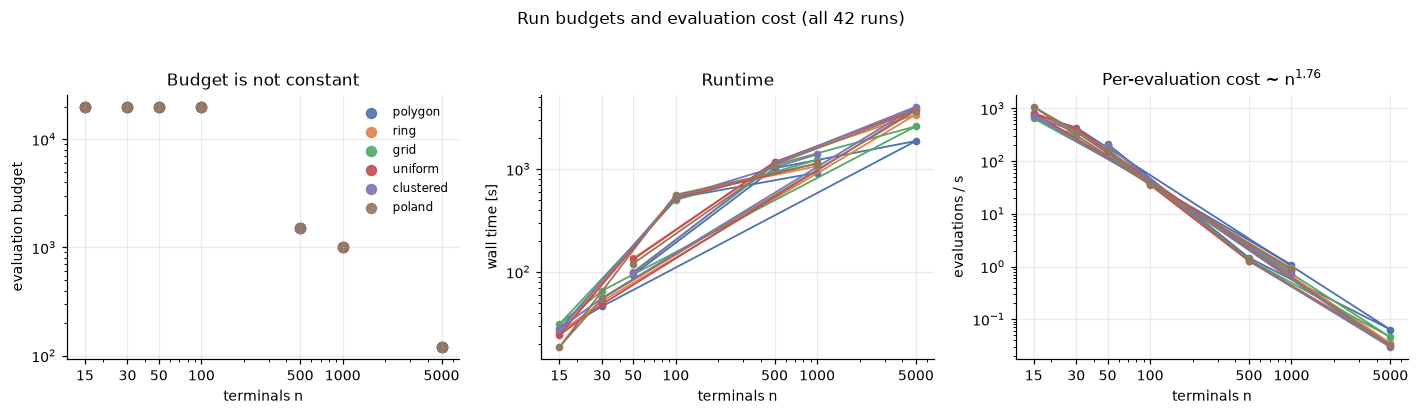

total compute across all runs: 10.4 CPU hours
per-evaluation time scales as n^1.76 (log-log fit over all runs)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

ax = axes[0]
for fam in families:
    subset = [r for r in RUNS if r["family"] == fam]
    ax.scatter([r["n"] for r in subset], [r["evals"] for r in subset],
               color=FAMILY_COLOR[fam], label=fam, s=42, alpha=0.9)
ax.set(xscale="log", yscale="log", xlabel="terminals n", ylabel="evaluation budget",
       title="Budget is not constant")
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)
ax.legend(fontsize=8)

ax = axes[1]
for fam in families:
    subset = [r for r in RUNS if r["family"] == fam]
    ax.plot([r["n"] for r in subset], [r["runtime"] for r in subset],
            "o-", color=FAMILY_COLOR[fam], label=fam, ms=4, lw=1.2)
ax.set(xscale="log", yscale="log", xlabel="terminals n", ylabel="wall time [s]",
       title="Runtime")
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)

n_arr = np.array([r["n"] for r in RUNS], dtype=float)
t_arr = np.array([r["runtime"] for r in RUNS])
evals_arr = np.array([r["evals"] for r in RUNS], dtype=float)
per_eval = t_arr / evals_arr
cost_slope, _ = np.polyfit(np.log(n_arr), np.log(per_eval), 1)

ax = axes[2]
for fam in families:
    subset = [r for r in RUNS if r["family"] == fam]
    ax.plot([r["n"] for r in subset], [r["evals_per_s"] for r in subset],
            "o-", color=FAMILY_COLOR[fam], label=fam, ms=4, lw=1.2)
ax.set(xscale="log", yscale="log", xlabel="terminals n", ylabel="evaluations / s",
       title=f"Per-evaluation cost ~ n$^{{{cost_slope:.2f}}}$")
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)

fig.suptitle("Run budgets and evaluation cost (all 42 runs)", y=1.03)
fig.tight_layout()
savefig(fig, "01_budgets_and_cost.png")

print(f"total compute across all runs: {t_arr.sum() / 3600:.1f} CPU hours")
print(f"per-evaluation time scales as n^{cost_slope:.2f} (log-log fit over all runs)")

## 2. Final objective value

`J = 0.4·C/C_MST + 0.4·D/D_MST + 0.2·(1−FT)`. The terminal-only MST baseline is `J = 1`,
so anything below 1 is an improvement. The left heatmap shows the raw final value; the
right one ranks families **within each size**, which removes the size effect.

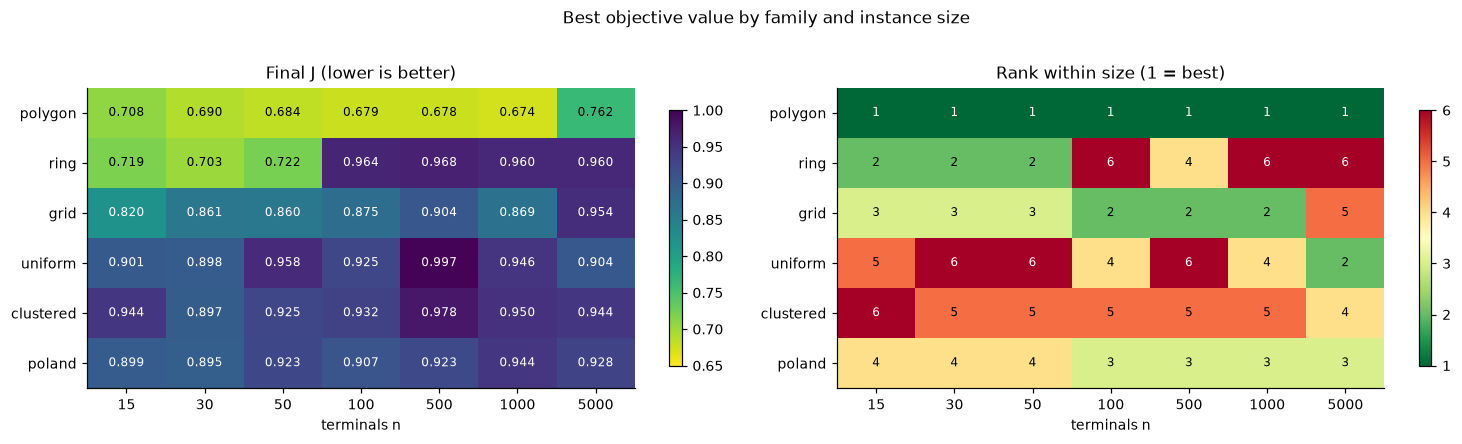

| family | best size | min J | worst size | max J | mean J |
| --- | --- | --- | --- | --- | --- |
| polygon | 1000 | 0.6745 | 5000 | 0.7624 | 0.6965 |
| ring | 30 | 0.7033 | 500 | 0.9678 | 0.8566 |
| grid | 15 | 0.8200 | 5000 | 0.9536 | 0.8775 |
| uniform | 30 | 0.8984 | 500 | 0.9970 | 0.9328 |
| clustered | 30 | 0.8972 | 500 | 0.9775 | 0.9387 |
| poland | 30 | 0.8947 | 1000 | 0.9442 | 0.9170 |

lowest final J : polygon_1000_seed42 (0.6745, 1,000 evals)
highest final J: uniform_500_seed42 (0.9970, 1,500 evals)


In [5]:
J = np.array([[by_key[(f, s)]["J"] for s in sizes] for f in families])
R = np.array([[by_key[(f, s)]["J_common"] for s in sizes] for f in families])
with np.errstate(invalid="ignore"):
    rank = np.array([
        [int(np.where(np.argsort(np.array([by_key[(f, s)]["J"] for f in families])) == i)[0][0]) + 1
         for s in sizes]
        for i, f in enumerate(families)
    ])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
for ax, data, title, cmap, vmin, vmax, fmt in [
    (axes[0], J, "Final J (lower is better)", "viridis_r", 0.65, 1.0, "{:.3f}"),
    (axes[1], rank, "Rank within size (1 = best)", "RdYlGn_r", 1, len(families), "{:.0f}"),
]:
    im = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(sizes)), sizes)
    ax.set_yticks(range(len(families)), families)
    ax.set_xlabel("terminals n")
    ax.set_title(title)
    ax.grid(False)
    for i in range(len(families)):
        for j in range(len(sizes)):
            rgba = im.cmap(im.norm(data[i, j]))[:3]
            brightness = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center",
                    color="white" if brightness < 0.5 else "black", fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.85)

fig.suptitle("Best objective value by family and instance size", y=1.02)
fig.tight_layout()
savefig(fig, "02_final_score_heatmap.png")

display(md_table(
    ["family", "best size", "min J", "worst size", "max J", "mean J"],
    [[f,
      sizes[int(np.argmin(J[i]))], f"{J[i].min():.4f}",
      sizes[int(np.argmax(J[i]))], f"{J[i].max():.4f}", f"{J[i].mean():.4f}"]
     for i, f in enumerate(families)],
))

best_run = min(RUNS, key=lambda r: r["J"])
worst_run = max(RUNS, key=lambda r: r["J"])
print(f"lowest final J : {best_run['name']} ({best_run['J']:.4f}, {best_run['evals']:,} evals)")
print(f"highest final J: {worst_run['name']} ({worst_run['J']:.4f}, {worst_run['evals']:,} evals)")

## 3. Convergence

Best-so-far `J` against the evaluation counter. Lines stop at each run's own budget, so
the right-hand ends are not comparable. The second figure therefore compares all runs at
the **common budget of 120 evaluations**, and normalises progress by the improvement each
run actually achieved.

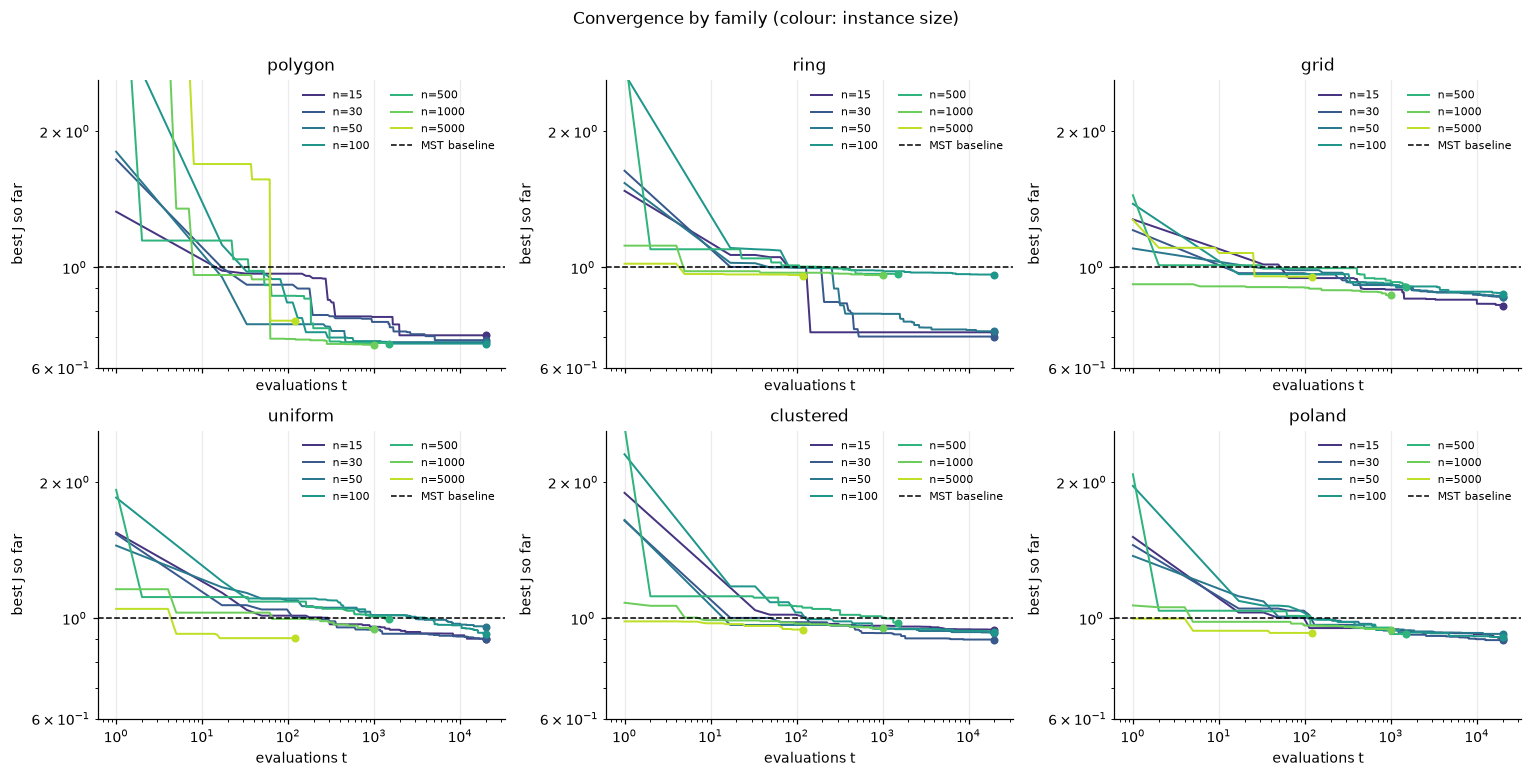

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
axes = axes.ravel()
for ax, fam in zip(axes, families):
    for r in sorted((r for r in RUNS if r["family"] == fam), key=lambda r: r["n"]):
        h = r["history"]
        step = max(1, len(h["t"]) // 1200)
        t = h["t"][::step]
        b = h["best"][::step]
        if t[-1] != h["t"][-1]:
            t = np.append(t, h["t"][-1])
            b = np.append(b, h["best"][-1])
        ax.plot(t, b, lw=1.3, color=size_color(r["n"]), label=f"n={r['n']}")
        ax.scatter([t[-1]], [b[-1]], color=size_color(r["n"]), s=18, zorder=5)
    ax.axhline(1.0, color="black", ls="--", lw=1, label="MST baseline")
    ax.set(xscale="log", yscale="log", ylim=(0.6, 2.6),
           title=f"{fam}", xlabel="evaluations t", ylabel="best J so far")
    ax.legend(fontsize=7, ncol=2)
fig.suptitle("Convergence by family (colour: instance size)", y=1.0)
fig.tight_layout()
savefig(fig, "03_convergence_by_family.png")

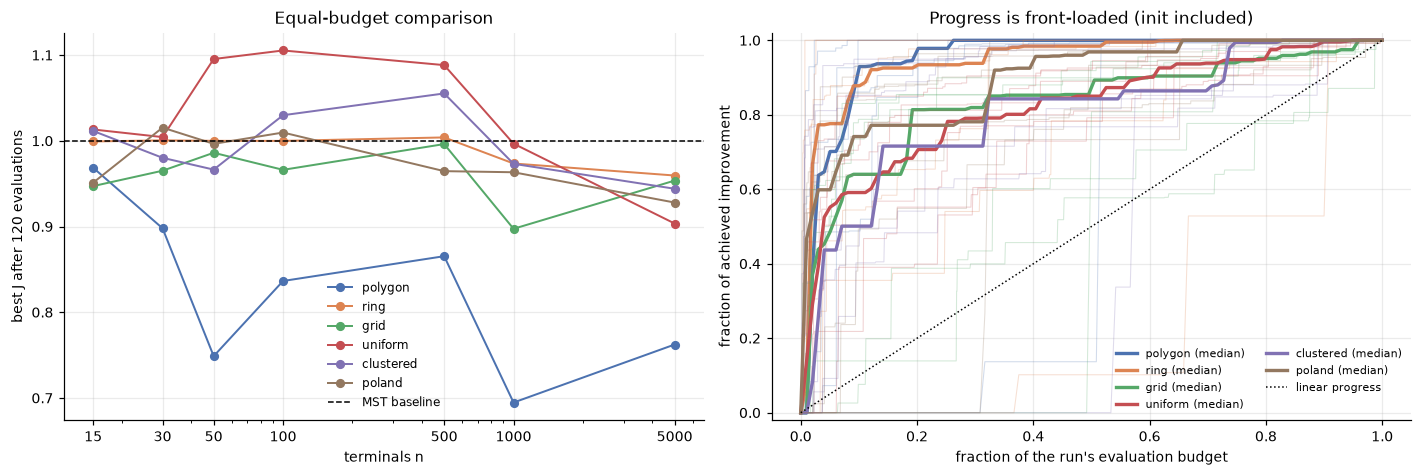

runs with no measurable improvement (excluded from right panel): 1


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

# (a) common-budget comparison
ax = axes[0]
for fam in families:
    subset = sorted((r for r in RUNS if r["family"] == fam), key=lambda r: r["n"])
    ax.plot([r["n"] for r in subset], [r["J_common"] for r in subset],
            "o-", color=FAMILY_COLOR[fam], label=fam, ms=5, lw=1.3)
ax.axhline(1.0, color="black", ls="--", lw=1, label="MST baseline")
ax.set(xscale="log", xlabel="terminals n",
       ylabel=f"best J after {COMMON_BUDGET} evaluations", title="Equal-budget comparison")
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)
ax.legend(fontsize=8)

# (b) normalised progress: share of a run's total improvement vs share of budget
ax = axes[1]
skipped = 0
for fam in families:
    curves = []
    for r in (r for r in RUNS if r["family"] == fam):
        h = r["history"]
        total = r["J_init"] - r["J"]
        if total < 1e-6:
            skipped += 1
            continue
        frac = h["t"] / h["t"][-1]
        progress = (r["J_init"] - h["best"]) / total
        curves.append((frac, np.clip(progress, 0, 1)))
        ax.plot(frac, np.clip(progress, 0, 1), color=FAMILY_COLOR[fam], lw=0.7, alpha=0.25)
    if curves:
        grid = np.linspace(0, 1, 100)
        med = np.median([np.interp(grid, f, p) for f, p in curves], axis=0)
        ax.plot(grid, med, color=FAMILY_COLOR[fam], lw=2.2, label=f"{fam} (median)")

ax.plot([0, 1], [0, 1], color="black", ls=":", lw=1, label="linear progress")
ax.set(xlabel="fraction of the run's evaluation budget",
       ylabel="fraction of achieved improvement", ylim=(-0.02, 1.02),
       title="Progress is front-loaded (init included)")
ax.legend(fontsize=7, ncol=2)

fig.tight_layout()
savefig(fig, "04_equal_budget_and_progress.png")
print(f"runs with no measurable improvement (excluded from right panel): {skipped}")

## 4. What drives the objective?

Splitting `J` into its three weighted terms shows *why* a family wins or loses: cheap
network (C-term), low detour (D-term) or fault tolerance (FT-term). Metrics are normalised
by the terminal-only MST, so they are comparable across sizes; FT is bounded in `[0, 1]`.

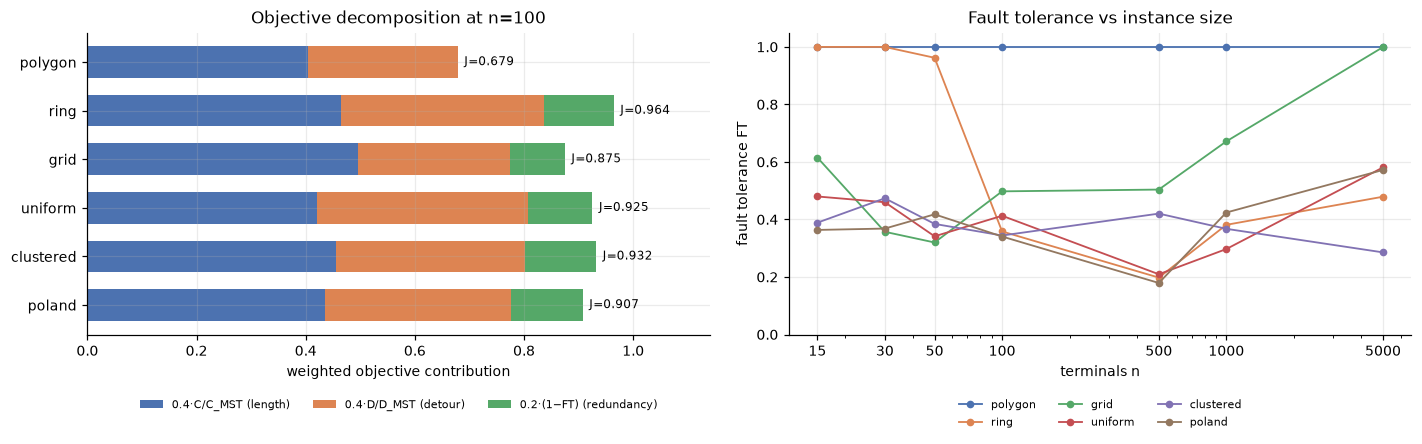

| family @ n=100 | C/C_MST | D/D_MST | FT | J |
| --- | --- | --- | --- | --- |
| polygon | 1.010 | 0.686 | 1.000 | 0.679 |
| ring | 1.161 | 0.930 | 0.358 | 0.964 |
| grid | 1.240 | 0.695 | 0.498 | 0.875 |
| uniform | 1.052 | 0.968 | 0.413 | 0.925 |
| clustered | 1.137 | 0.866 | 0.344 | 0.932 |
| poland | 1.087 | 0.853 | 0.341 | 0.907 |

In [8]:
# --- (a) stacked contribution of the three objective terms at n = 100
ref_n = 100 if 100 in sizes else sizes[len(sizes) // 2]
terms = []
for fam in families:
    r = by_key[(fam, ref_n)]
    m = r["metrics"]
    w = r["weights"]
    terms.append([
        w["w1"] * m["C"] / m["C_mst"],
        w["w2"] * m["D"] / m["D_mst"],
        w["w3"] * (1.0 - m["FT"]),
    ])
terms = np.array(terms)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
y = np.arange(len(families))
left = np.zeros(len(families))
labels = ["0.4·C/C_MST (length)", "0.4·D/D_MST (detour)", "0.2·(1−FT) (redundancy)"]
colors = ["#4C72B0", "#DD8452", "#55A868"]
for k in range(3):
    ax.barh(y, terms[:, k], left=left, color=colors[k], label=labels[k], height=0.65)
    left += terms[:, k]
for i, fam in enumerate(families):
    ax.text(left[i] + 0.012, i, f"J={left[i]:.3f}", va="center", fontsize=8)
ax.set_yticks(y, families)
ax.invert_yaxis()
ax.set(xlim=(0, 1.14), xlabel="weighted objective contribution",
       title=f"Objective decomposition at n={ref_n}")
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)

# --- (b) fault tolerance vs size
ax = axes[1]
for fam in families:
    subset = sorted((r for r in RUNS if r["family"] == fam), key=lambda r: r["n"])
    ax.plot([r["n"] for r in subset], [r["metrics"]["FT"] for r in subset],
            "o-", color=FAMILY_COLOR[fam], label=fam, ms=4, lw=1.2)
ax.set(xscale="log", xlabel="terminals n", ylabel="fault tolerance FT", ylim=(0, 1.05),
       title="Fault tolerance vs instance size")
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)

fig.tight_layout()
savefig(fig, "05_objective_decomposition.png")

display(md_table(
    ["family @ n=100", "C/C_MST", "D/D_MST", "FT", "J"],
    [[f,
      f"{by_key[(f, ref_n)]['metrics']['C'] / by_key[(f, ref_n)]['metrics']['C_mst']:.3f}",
      f"{by_key[(f, ref_n)]['metrics']['D'] / by_key[(f, ref_n)]['metrics']['D_mst']:.3f}",
      f"{by_key[(f, ref_n)]['metrics']['FT']:.3f}",
      f"{by_key[(f, ref_n)]['J']:.3f}"] for f in families],
))

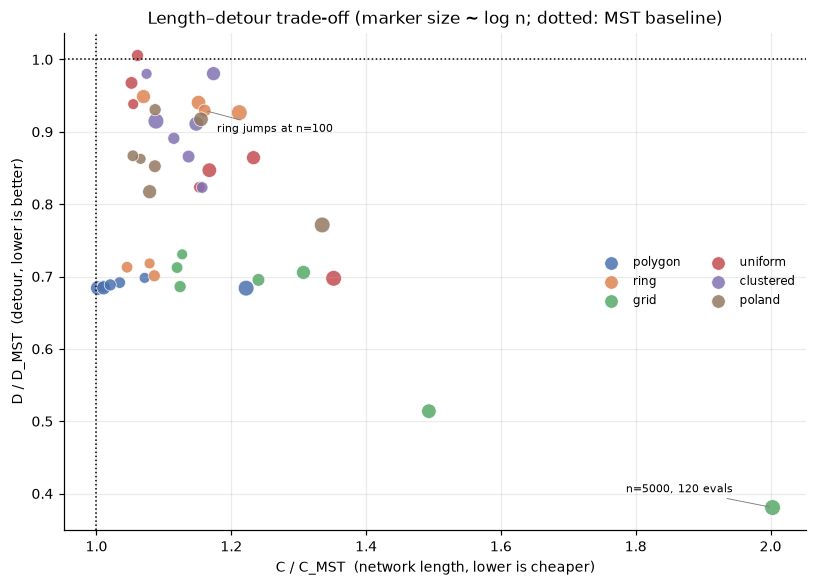

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5.4))
for fam in families:
    subset = [r for r in RUNS if r["family"] == fam]
    ax.scatter(
        [r["metrics"]["C"] / r["metrics"]["C_mst"] for r in subset],
        [r["metrics"]["D"] / r["metrics"]["D_mst"] for r in subset],
        s=25 + 22 * np.log10([r["n"] for r in subset]),
        color=FAMILY_COLOR[fam], label=fam, alpha=0.85, edgecolor="white", linewidth=0.5,
    )

for label, fam, n, offset in [
    ("ring jumps at n=100", "ring", 100, (8, -14)),
    ("n=5000, 120 evals", "grid", 5000, (-96, 10)),
]:
    r = by_key[(fam, n)]
    ax.annotate(label, (r["metrics"]["C"] / r["metrics"]["C_mst"],
                        r["metrics"]["D"] / r["metrics"]["D_mst"]),
                textcoords="offset points", xytext=offset, fontsize=7,
                arrowprops=dict(arrowstyle="-", lw=0.6, color="grey"))

ax.axhline(1.0, color="black", ls=":", lw=1)
ax.axvline(1.0, color="black", ls=":", lw=1)
ax.set(xlabel="C / C_MST  (network length, lower is cheaper)",
       ylabel="D / D_MST  (detour, lower is better)",
       title="Length–detour trade-off (marker size ~ log n; dotted: MST baseline)")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
savefig(fig, "06_cost_detour_tradeoff.png")

## 5. Search behaviour

How the optimizer spends its evaluations, how often proposals are accepted, how the
population spread collapses, and how much redundancy (`theta`) it chooses. Operator
statistics are shown for `n = 100`, where every family got the same 20,000-evaluation
budget.

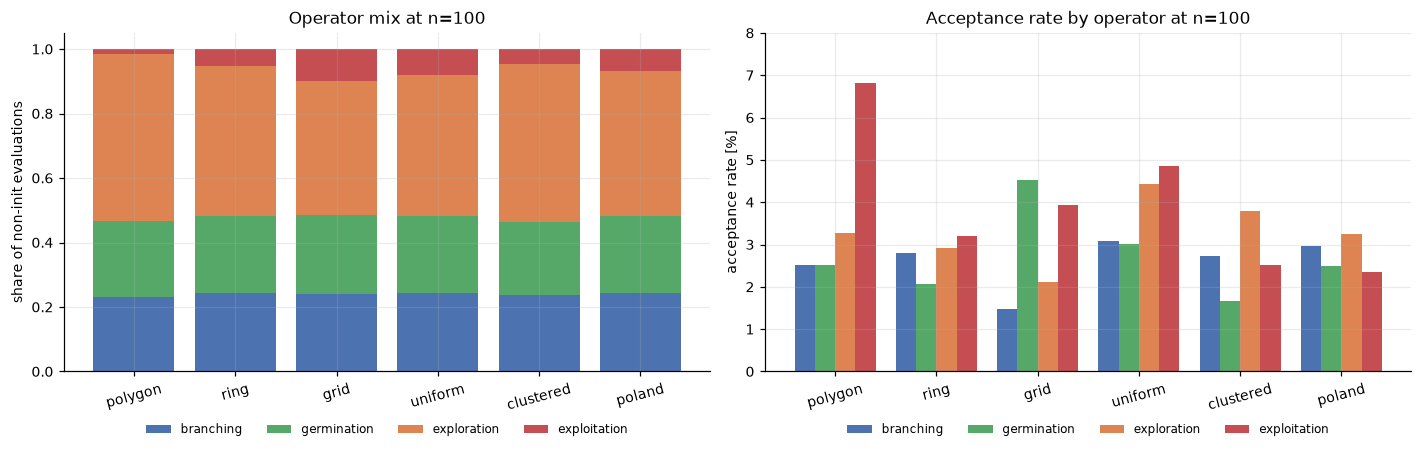

| operator | evaluations (n=100, all families) | accepted | acceptance rate |
| --- | --- | --- | --- |
| branching | 28,699 | 745 | 2.6% |
| germination | 28,531 | 777 | 2.7% |
| exploration | 55,241 | 1,825 | 3.3% |
| exploitation | 7,349 | 271 | 3.7% |

In [10]:
ref_n = 100 if 100 in sizes else sizes[len(sizes) // 2]
ops = ["branching", "germination", "exploration", "exploitation"]

share = np.zeros((len(families), len(ops)))
accept = np.full((len(families), len(ops)), np.nan)
overall = {op: [0, 0] for op in ops}

for i, fam in enumerate(families):
    h = by_key[(fam, ref_n)]["history"]
    mask = h["phase"] != "init"
    total = mask.sum()
    for j, op in enumerate(ops):
        m = mask & (h["operator"] == op)
        share[i, j] = m.sum() / total if total else 0
        if m.any():
            accept[i, j] = h["accepted"][m].mean()
        overall[op][0] += int(m.sum())
        overall[op][1] += int(h["accepted"][m].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bottom = np.zeros(len(families))
for j, op in enumerate(ops):
    ax.bar(families, share[:, j], bottom=bottom, color=OPERATOR_COLOR[op], label=op)
    bottom += share[:, j]
ax.set(ylabel="share of non-init evaluations", title=f"Operator mix at n={ref_n}")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.tick_params(axis="x", rotation=15)

ax = axes[1]
width = 0.2
x = np.arange(len(families))
for j, op in enumerate(ops):
    ax.bar(x + (j - 1.5) * width, accept[:, j] * 100, width,
           color=OPERATOR_COLOR[op], label=op)
ax.set_xticks(x, families)
ax.set(ylabel="acceptance rate [%]", title=f"Acceptance rate by operator at n={ref_n}",
       ylim=(0, 8))
ax.tick_params(axis="x", rotation=15)
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))

fig.tight_layout()
savefig(fig, "07_operator_behaviour.png")

display(md_table(
    ["operator", "evaluations (n=100, all families)", "accepted", "acceptance rate"],
    [[op, f"{overall[op][0]:,}", f"{overall[op][1]:,}",
      f"{100 * overall[op][1] / max(overall[op][0], 1):.1f}%"] for op in ops],
))

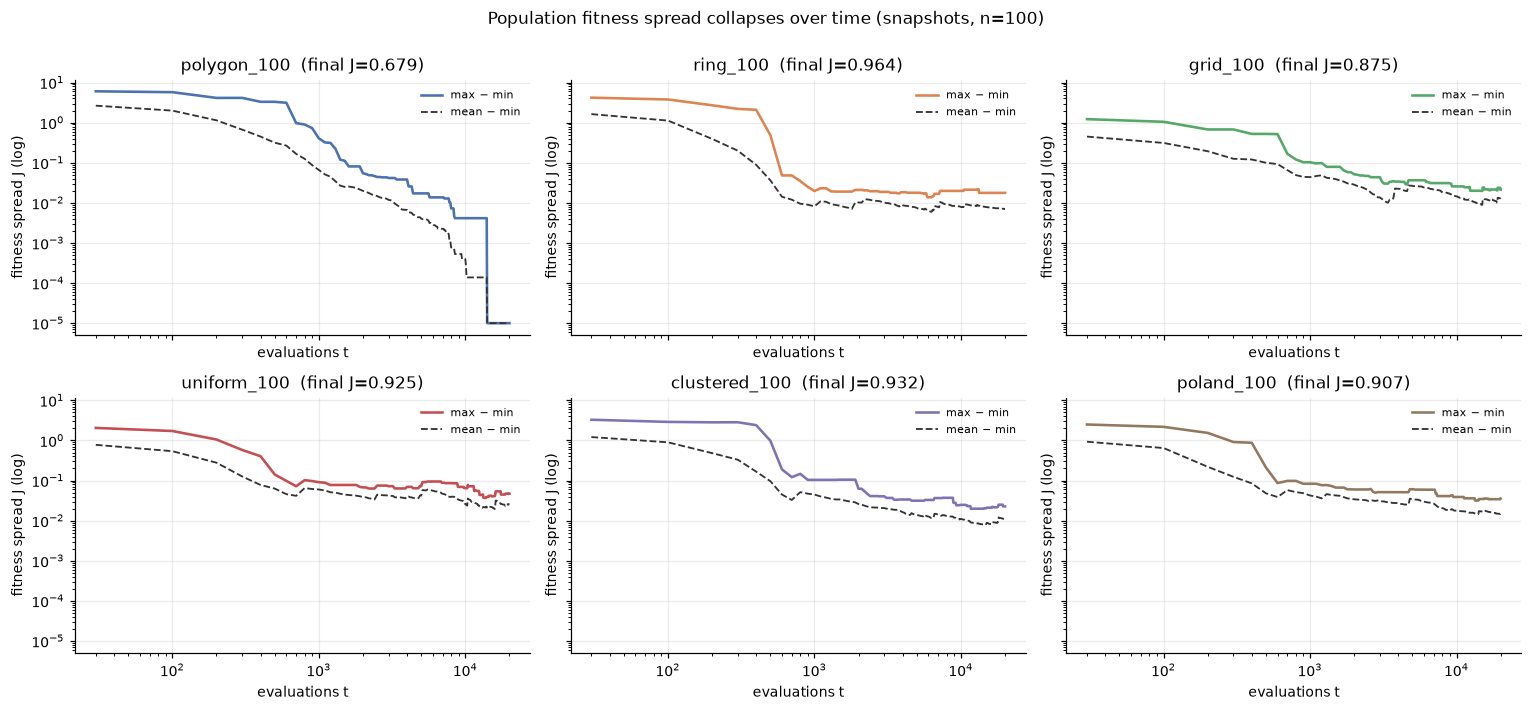

In [11]:
ref_n = 100 if 100 in sizes else sizes[len(sizes) // 2]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4), sharex=True, sharey=True)
axes = axes.ravel()
for ax, fam in zip(axes, families):
    r = by_key[(fam, ref_n)]
    s = r["snapshots"]
    spread_max = np.maximum(s["fmax"] - s["fmin"], 1e-5)
    spread_mean = np.maximum(s["fmean"] - s["fmin"], 1e-5)
    ax.plot(s["t"], spread_max, color=FAMILY_COLOR[fam], lw=1.7, label="max − min")
    ax.plot(s["t"], spread_mean, color="#333333", lw=1.2, ls="--", label="mean − min")
    ax.set(xscale="log", yscale="log", title=f"{fam}_{ref_n}  (final J={r['J']:.3f})",
           xlabel="evaluations t")
    ax.set_ylabel("fitness spread J (log)")
    ax.legend(fontsize=7)
fig.suptitle(f"Population fitness spread collapses over time (snapshots, n={ref_n})", y=1.0)
fig.tight_layout()
savefig(fig, "08_population_dynamics.png")

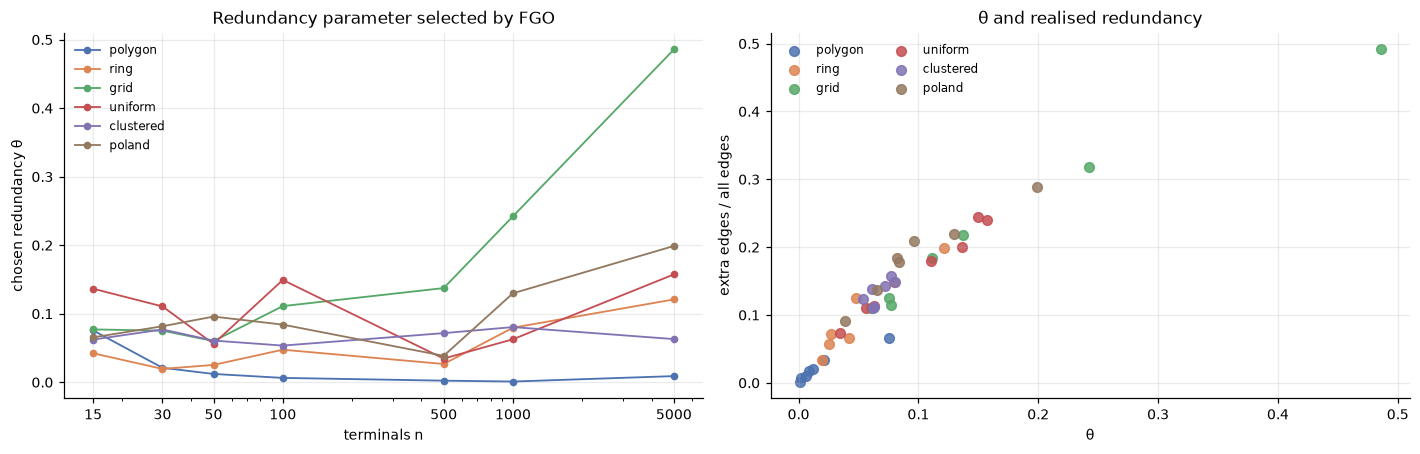

most MST-like runs (θ≈0): polygon_1000_seed42 (0.0011), polygon_500_seed42 (0.0024), polygon_100_seed42 (0.0064), polygon_5000_seed42 (0.0090)
most redundant runs      : uniform_5000_seed42 (0.157), poland_5000_seed42 (0.199), grid_1000_seed42 (0.242), grid_5000_seed42 (0.486)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
for fam in families:
    subset = sorted((r for r in RUNS if r["family"] == fam), key=lambda r: r["n"])
    ax.plot([r["n"] for r in subset], [r["theta"] for r in subset],
            "o-", color=FAMILY_COLOR[fam], label=fam, ms=4, lw=1.2)
ax.set(xscale="log", xlabel="terminals n", ylabel="chosen redundancy θ",
       title="Redundancy parameter selected by FGO")
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)
ax.legend(fontsize=8)

ax = axes[1]
for fam in families:
    subset = [r for r in RUNS if r["family"] == fam]
    ax.scatter([r["theta"] for r in subset],
               [r["metrics"]["extra_edge_count"] / max(r["metrics"]["edge_count"], 1) for r in subset],
               color=FAMILY_COLOR[fam], label=fam, s=40, alpha=0.85)
ax.set(xlabel="θ", ylabel="extra edges / all edges",
       title="θ and realised redundancy")
ax.legend(fontsize=8, ncol=2)

fig.tight_layout()
savefig(fig, "09_redundancy.png")

flat = sorted(RUNS, key=lambda r: r["theta"])
print("most MST-like runs (θ≈0):", ", ".join(f"{r['name']} ({r['theta']:.4f})" for r in flat[:4]))
print("most redundant runs      :", ", ".join(f"{r['name']} ({r['theta']:.3f})" for r in flat[-4:]))

## 6. Best networks found

The decoded best solution for one representative run per family (`n = 100`). Terminals are
black, Steiner points grey, MST edges blue and the additional (redundancy) Delaunay edges
orange. All coordinates are normalised to the unit square during decoding.

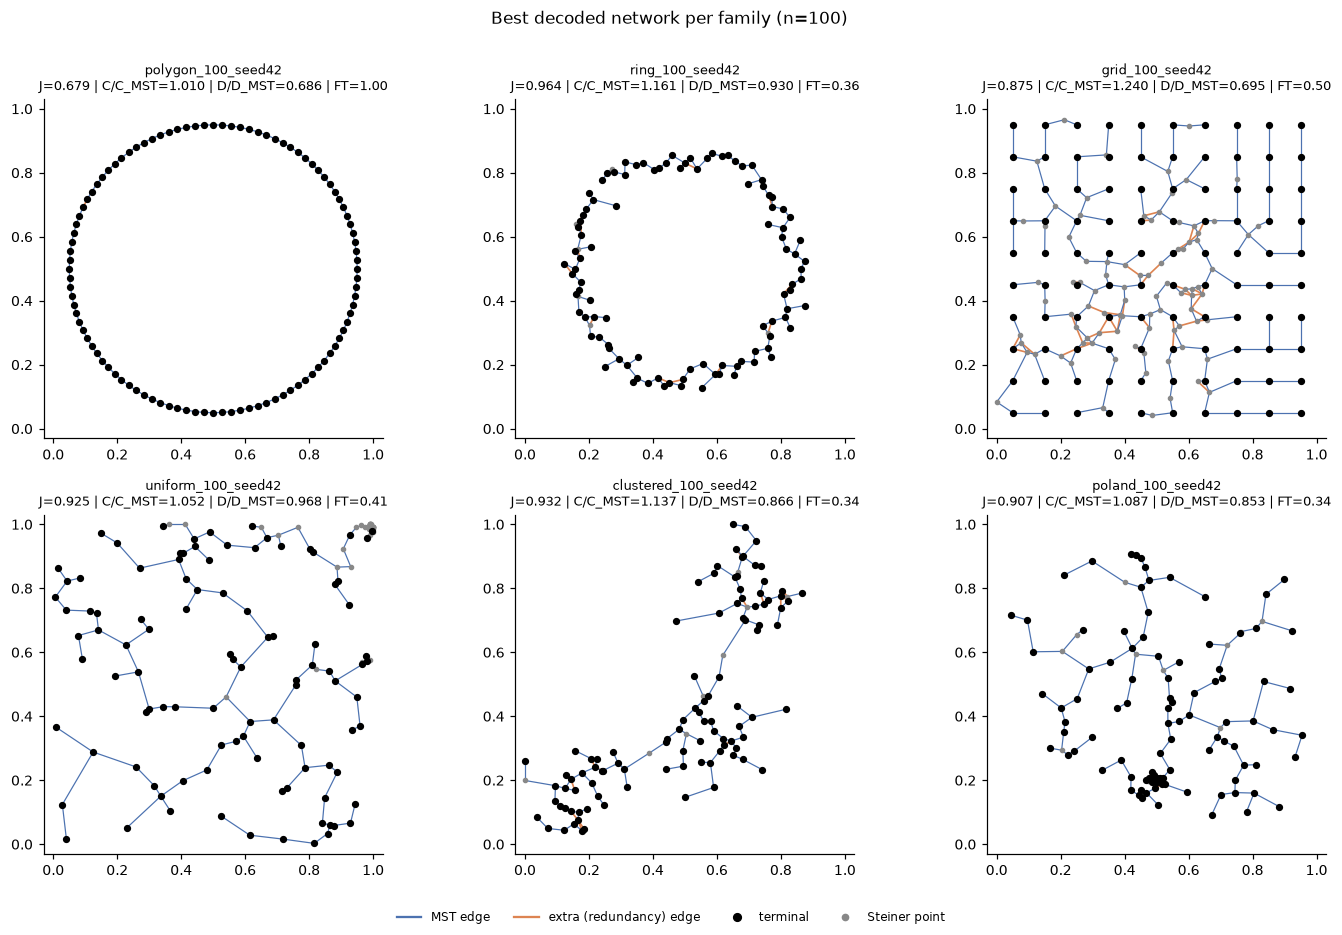

In [13]:
ref_n = 100 if 100 in sizes else sizes[len(sizes) // 2]
fig, axes = plt.subplots(2, 3, figsize=(13, 8.4))
axes = axes.ravel()

for ax, fam in zip(axes, families):
    r = by_key[(fam, ref_n)]
    g = r["graph"]
    pts = np.array(g["points"], dtype=float)
    n_term = g["terminal_count"]
    mst = [(e["u"], e["v"]) for e in g["edges"] if e["kind"] == "mst"]
    extra = [(e["u"], e["v"]) for e in g["edges"] if e["kind"] != "mst"]

    for u, v in extra:
        ax.plot(pts[[u, v], 0], pts[[u, v], 1], color="#DD8452", lw=1.1, zorder=2)
    for u, v in mst:
        ax.plot(pts[[u, v], 0], pts[[u, v], 1], color="#4C72B0", lw=0.8, zorder=3)
    used = {i for e in g["edges"] for i in (e["u"], e["v"])}
    steiner = [i for i in range(n_term, len(pts)) if i in used]
    ax.scatter(pts[steiner, 0], pts[steiner, 1], s=7, color="#888888", zorder=4)
    ax.scatter(pts[:n_term, 0], pts[:n_term, 1], s=14, color="black", zorder=5)

    m = r["metrics"]
    ax.set_title(f"{r['name']}\nJ={r['J']:.3f} | C/C_MST={m['C'] / m['C_mst']:.3f} "
                 f"| D/D_MST={m['D'] / m['D_mst']:.3f} | FT={m['FT']:.2f}", fontsize=8.5)
    ax.set_aspect("equal")
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.grid(False)

from matplotlib.lines import Line2D
handles = [
    Line2D([], [], color="#4C72B0", lw=1.5, label="MST edge"),
    Line2D([], [], color="#DD8452", lw=1.5, label="extra (redundancy) edge"),
    Line2D([], [], marker="o", color="black", ls="", ms=5, label="terminal"),
    Line2D([], [], marker="o", color="#888888", ls="", ms=4, label="Steiner point"),
]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8)
fig.suptitle("Best decoded network per family (n=100)", y=0.995)
fig.tight_layout(rect=(0, 0.04, 1, 0.99))
savefig(fig, "10_best_networks.png")

## 7. Automatic summary

A compact, data-derived recap (all numbers recomputed from the files above).

In [14]:
from scipy.stats import spearmanr

print("BUDGETS")
for s in sizes:
    print(f"  n={s:>4}: {evals_by_size[s][0]:,} evals")

print("\nFINAL QUALITY (within-family, across sizes)")
for fam in families:
    subset = [r for r in RUNS if r["family"] == fam]
    print(f"  {fam:<10} J {min(r['J'] for r in subset):.3f}..{max(r['J'] for r in subset):.3f}"
          f"  | mean improvement after init {np.mean([r['J_init'] - r['J'] for r in subset]):.3f}"
          f"  | Spearman(n, J)={spearmanr([r['n'] for r in subset], [r['J'] for r in subset]).statistic:+.2f}")

print("\nEQUAL BUDGET (t=120)")
for fam in families:
    subset = [r for r in RUNS if r["family"] == fam]
    print(f"  {fam:<10} mean J@120={np.mean([r['J_common'] for r in subset]):.3f}"
          f" -> mean final J={np.mean([r['J'] for r in subset]):.3f}")

print("\nRUNTIME")
print(f"  total {t_arr.sum() / 3600:.1f} h | slowest {max(RUNS, key=lambda r: r['runtime'])['name']}"
      f" ({max(r['runtime'] for r in RUNS) / 3600:.2f} h)"
      f" | fastest {min(RUNS, key=lambda r: r['runtime'])['name']}"
      f" ({min(r['runtime'] for r in RUNS):.1f} s)")
print(f"  per-evaluation time scales as n^{cost_slope:.2f}")
print(f"  total evaluations parsed: {sum(r['evals'] for r in RUNS):,}")

print("\nSEARCH")
op_tot = {op: sum(int((r['history']['operator'] == op).sum()) for r in RUNS) for op in ops}
grand = sum(op_tot.values())
for op in ops:
    print(f"  {op:<12} {100 * op_tot[op] / grand:5.1f}% of all evaluations")
poly = by_key[("polygon", 100)]
print(f"  polygon_100 θ={poly['theta']:.4f}; grid_5000 θ={by_key[('grid', 5000)]['theta']:.3f}")

print("\nBIGGEST IMPROVEMENTS (init -> final)")
for r in sorted(RUNS, key=lambda r: r["J_init"] - r["J"], reverse=True)[:5]:
    print(f"  {r['name']:<24} {r['J_init']:.3f} -> {r['J']:.3f}  (Δ={r['J_init'] - r['J']:+.3f})")

BUDGETS
  n=  15: 20,000 evals
  n=  30: 20,000 evals
  n=  50: 20,000 evals
  n= 100: 20,000 evals
  n= 500: 1,500 evals
  n=1000: 1,000 evals
  n=5000: 120 evals

FINAL QUALITY (within-family, across sizes)
  polygon    J 0.674..0.762  | mean improvement after init 0.348  | Spearman(n, J)=-0.25
  ring       J 0.703..0.968  | mean improvement after init 0.169  | Spearman(n, J)=+0.64
  grid       J 0.820..0.954  | mean improvement after init 0.097  | Spearman(n, J)=+0.86
  uniform    J 0.898..0.997  | mean improvement after init 0.125  | Spearman(n, J)=+0.43
  clustered  J 0.897..0.978  | mean improvement after init 0.098  | Spearman(n, J)=+0.64
  poland     J 0.895..0.944  | mean improvement after init 0.111  | Spearman(n, J)=+0.82

EQUAL BUDGET (t=120)
  polygon    mean J@120=0.825 -> mean final J=0.696
  ring       mean J@120=0.991 -> mean final J=0.857
  grid       mean J@120=0.959 -> mean final J=0.878
  uniform    mean J@120=1.030 -> mean final J=0.933
  clustered  mean J@120=0.9

## 8. Findings

**Dataset and budget.** 42 runs, 6 families × 7 sizes, all seed 42: 495,720 evaluations and
10.4 CPU-hours. The budget is *not* uniform — 20,000 evaluations for n ≤ 100, 1,500 for
n = 500, 1,000 for n = 1,000 and only **120** for n = 5,000. Evaluation cost grows roughly
as n^1.8 (K is capped at 200 for n ≥ 1,000), so the largest runs are both the most
expensive per evaluation and the least converged.

**Quality.** `polygon` is the best family at every size (7/7 rank-1 finishes, J = 0.674–0.762)
and `clustered`/`uniform` are consistently the worst (J ≈ 0.90–1.00). `poland` sits in the
middle (0.895–0.944). Best single result: `polygon_1000` (J = 0.6745); worst: `uniform_500`
(J = 0.9970). Within families, J rises with n for every family except polygon
(Spearman(n, J) = +0.43 … +0.86), which is consistent with the shrinking budget and growing
search dimension rather than with the instance geometry alone.

**Convergence.** Most improvement happens in the first few hundred evaluations. Mean
improvement after initialization is largest for polygon (+0.348) and smallest for grid
(+0.097) and clustered (+0.098). At the common budget of 120 evaluations the family means
are nearly indistinguishable (0.825–1.030) and far from the final values of the runs that
received more budget, so final rankings mostly reflect how much budget each size got rather
than instance difficulty. The n = 5,000 runs are essentially "initialization plus 90 proposals":
uniform_5000 recorded **no** measurable improvement, ring/grid/poland improved by ≤ 0.02,
and only polygon_5000 improved a lot (1.693 → 0.762) because its initial population was poor.

**Where J comes from.** `polygon` wins on detour (D/D_MST ≈ 0.68) while keeping FT = 1.0;
`grid` also has low detour (0.70 at n = 100) but pays 1.24× the MST length and loses FT.
`ring` breaks sharply at n = 100: J jumps from 0.72 (n = 50) to 0.96, FT falls from 0.96 to
0.36 and the length ratio rises to 1.16 — a ring is cheap to connect but its redundancy is
expensive to recover once the terminal count grows. `clustered` and `uniform` stay
detour-limited at every size (D/D_MST ≈ 0.82–1.01), which keeps their J close to or above
0.9.

**Search behaviour.** Exploration dominates (45.5% of evaluations), branching and
germination take ~24.5% each and exploitation only 5.6%. Acceptance is very low — 3.2%
overall (exploitation 4.5%, exploration 3.4%, germination 3.1%, branching 2.8%) — so ~97% of
proposals are rejected. Population fitness spread (max−min) falls by roughly 2–6 orders of
magnitude over a run, i.e. the population collapses onto a narrow basin early; the remaining
budget mostly refines `theta` and Steiner positions.

**Redundancy.** `polygon` drives θ to ≈0 (0.001–0.009 for n ≥ 500), i.e. it recovers the
terminal MST almost exactly. `grid` moves the other way (θ = 0.486 at n = 5,000, extra edges
are 49% of the network) trading length for detour; `poland` and `uniform` also become more
redundant with size. At n = 5,000, grid reaches the lowest detour ratio of all runs (0.38)
but at 2.0× the MST length — the clearest length↔detour trade-off in the dataset.

**Caveats.** There is one seed per configuration, so differences of a few thousandths are
noise; no confidence intervals can be computed from these files. `J` is normalised per
instance, so values are not comparable across families or sizes in an absolute sense —
compare ranks at fixed size, or J at fixed budget. The 120-evaluation equal-budget slice is
far below the 20,000-evaluation regime, so it measures early progress, not asymptotic
quality. Instance geometries also differ (unit square vs Poland), which limits causal
claims about family difficulty.